In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# To Do:

# Data Anomalies

# Class Distribution DONE

# Label Correctness (Code DONE, Action TBD)

# Visual Variety (Code DONE, Action TBD)

# Resolution Distribution DONE

# Aspect Ratios DONE

# Color Channels DONE

# Channel Histogram DONE


In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from tqdm import tqdm
from PIL import Image

In [3]:
DATA_DIR = "/content/drive/MyDrive/FDL Project/data/flower_photos_eda"

## Data Anomalies

In [4]:
pip install ImageHash pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 6.2 MB/s eta 0:00:00


In [4]:
import imagehash
from PIL import Image

In [5]:
hash_dict = {}
valid_extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.tiff', '.webp')

In [6]:
for root, dirs, files in os.walk(DATA_DIR):
    for filename in tqdm(files, desc=f"Hashing {os.path.basename(root)}"):
        if filename.lower().endswith(valid_extensions):
            filepath = os.path.join(root, filename)

            try:
                with Image.open(filepath) as img:
                    img_hash = str(imagehash.phash(img))

                    if img_hash not in hash_dict:
                        hash_dict[img_hash] = []
                    hash_dict[img_hash].append(filepath)

            except Exception as e:
                tqdm.write(f"Skipping unreadable/corrupt file: {filepath} | {e}")

Hashing roses: 100%|██████████| 641/641 [00:05<00:00, 119.51it/s]


In [7]:
total_duplicates_found = 0

print("DUPLICATE REPORT")
for img_hash, paths in hash_dict.items():
    if len(paths) > 1:
        total_duplicates_found += (len(paths) - 1)
        print(f"Found {len(paths)} copies of the same image (Hash: {img_hash}):")

        original = paths[0]
        print(f" - KEEPING: {original}")

        for duplicate_path in paths[1:]:
            print(f" - DUPLICATE: {duplicate_path}")
            # Delete duplicates if needed
            # os.remove(duplicate_path)

DUPLICATE REPORT


In [8]:
for img_hash, paths in hash_dict.items():
    if len(paths) > 1:
        folders = [os.path.basename(os.path.dirname(p)) for p in paths]

        # Scenario A: All duplicates belong to the SAME class (Intra-class)
        if len(set(folders)) == 1:
            print(f"[Auto-Cleaning] Found {len(paths)} copies inside the '{folders[0]}' folder.")
            print(f" - KEPT: {paths[0]}")
            for duplicate_path in paths[1:]:
                print(f" - DELETED: {duplicate_path}")
                os.remove(duplicate_path)

        # Scenario B: Image spans across DIFFERENT classes (Inter-class contamination)
        else:
            print("WARNING: Same image found in MULTIPLE categories!")
            for idx, path in enumerate(paths):
                print(f"[{idx}] {path}")

            while True:
                user_input = input(f"Enter the number [0-{len(paths)-1}] of the file you want to KEEP (all others will be deleted): ").strip()
                if user_input.isdigit() and 0 <= int(user_input) < len(paths):
                    keep_idx = int(user_input)
                    break
                print("Invalid choice. Please enter a valid number from the list.")

            for idx, path in enumerate(paths):
                if idx == keep_idx:
                    print(f" - KEPT: {path}")
                else:
                    print(f" - DELETED: {path}")
                    os.remove(path)

## Data Distribution

In [9]:
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
class_counts = {}

for folder in os.listdir(DATA_DIR):
  folder_path = os.path.join(DATA_DIR, folder)

  if os.path.isdir(folder_path):
    num_images = sum(
            1
            for f in os.listdir(folder_path)
            if f.lower().endswith(valid_extensions)
        )

    print(f"Folder: {folder}, Number of Images: {num_images}")
    class_counts[folder] = num_images

Folder: tulips, Number of Images: 798
Folder: daisy, Number of Images: 631
Folder: sunflowers, Number of Images: 697
Folder: dandelion, Number of Images: 898
Folder: roses, Number of Images: 641


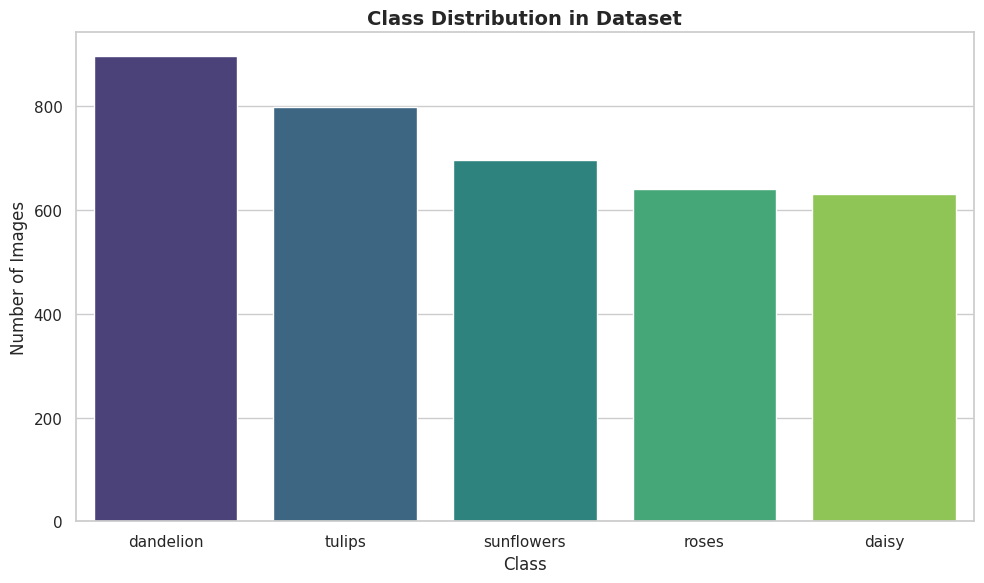

In [10]:
df_class = pd.DataFrame(list(class_counts.items()), columns=['Class', 'Count'])
df_class.sort_values(by='Count', ascending=False, inplace=True)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(x="Class", y="Count", data=df_class, ax=ax, palette="viridis", hue="Class")

ax.set_title("Class Distribution in Dataset", fontsize=14, fontweight="bold")
ax.set_xlabel("Class", fontsize=12)
ax.set_ylabel("Number of Images", fontsize=12)

plt.tight_layout()

The dataset exhibits a mild class imbalance rather than a uniform distribution, ranging from roughly 630 to 900 images per category.

Dandelion is the most represented class with nearly 900 images, followed by tulips (~800 images).

Sunflowers sits in the middle with approximately 700 images.

Roses and daisy have the lowest counts, both hovering around 630–640 images.

## Visual Inspection

In [22]:
!pip install "Pillow<11.0.0" fiftyone --upgrade

INFO: pip is looking at multiple versions of fiftyone to determine which version is compatible with other requirements. This could take a while.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 42.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 82.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.9/112.9 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.5/112.5 kB 10.0 MB/s eta 0:00:00
   ━━━

In [11]:
import fiftyone as fo

In [12]:
fo.config.desktop_app = False

dataset = fo.Dataset.from_dir(
    dataset_dir=DATA_DIR,
    dataset_type=fo.types.ImageClassificationDirectoryTree,
    name="my_colab_dataset",
    overwrite=True
)

session = fo.launch_app(dataset)

Output hidden; open in https://colab.research.google.com to view.

Findings:

## Image Metadata

In [13]:
valid_extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.tiff', '.webp')

In [14]:
image_dimensions = {}

for folder in os.listdir(DATA_DIR):
  if os.path.isdir(os.path.join(DATA_DIR, folder)):
    image_dimensions[folder] = {"widths" : [], "heights" : [], "ratios" : [], "modes" : []}

    for filename in tqdm(os.listdir(os.path.join(DATA_DIR, folder)), desc=f"Processing {folder}"):
      if filename.lower().endswith(valid_extensions):
          filepath = os.path.join(DATA_DIR, folder, filename)

          try:
              with Image.open(filepath) as img:
                  w, h = img.size
                  mode = img.mode
                  ratio = round(w / h, 3)

                  image_dimensions[folder]["widths"].append(w)
                  image_dimensions[folder]["heights"].append(h)
                  image_dimensions[folder]["ratios"].append(ratio)
                  image_dimensions[folder]["modes"].append(mode)
          except Exception as e:
              print(f"Skipping corrupt or unreadable file {filename}: {e}")


Processing roses: 100%|██████████| 641/641 [00:02<00:00, 224.10it/s]


In [15]:
records = []
for class_name, data in image_dimensions.items():
    for w, h, r, m in zip(data["widths"], data["heights"], data["ratios"], data["modes"]):
        records.append({
            "Class": class_name,
            "Width": w,
            "Height": h,
            "Aspect_Ratio": r,
            "Color_Channel": m
        })

df_image_metadata = pd.DataFrame(records)

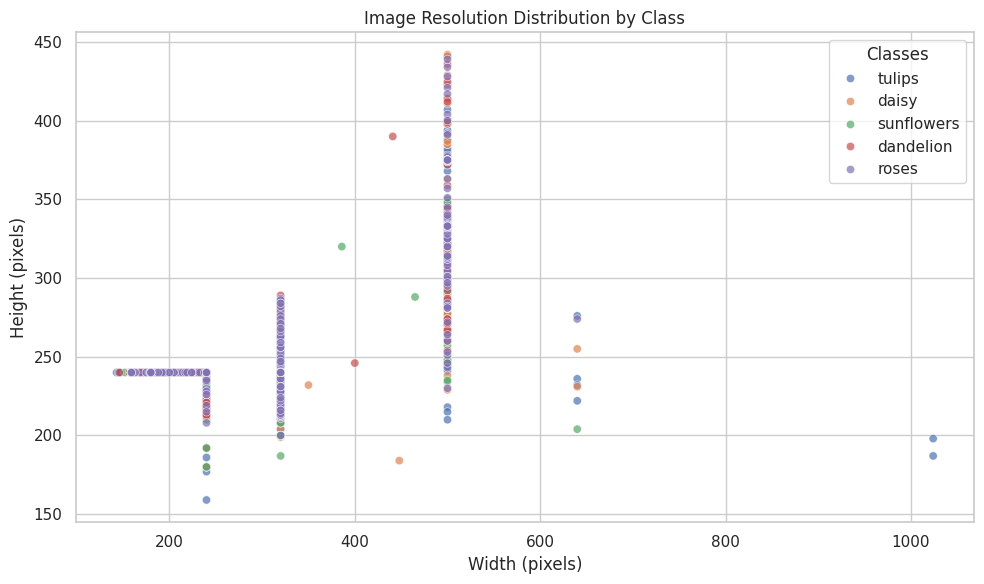

In [16]:
# 2. Plot using Seaborn (hue="Class" automatically separates them by folder)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_image_metadata, x="Width", y="Height", hue="Class", alpha=0.7)
plt.title("Image Resolution Distribution by Class")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.legend(title="Classes")
plt.tight_layout()
plt.savefig("resolution_by_class.png")
plt.show()

Every class (tulips, daisy, sunflowers, dandelion, roses) is present across all major clusters, confirming that image dimensions are an artifact of dataset curation rather than a class-dependent feature.

Since median image sizes sit around $500 \times 333$ or $320 \times 240$, standard CNN target resolutions like $224 \times 224$ are well-suited here; they require minimal downsampling without significant loss of fine floral detail.

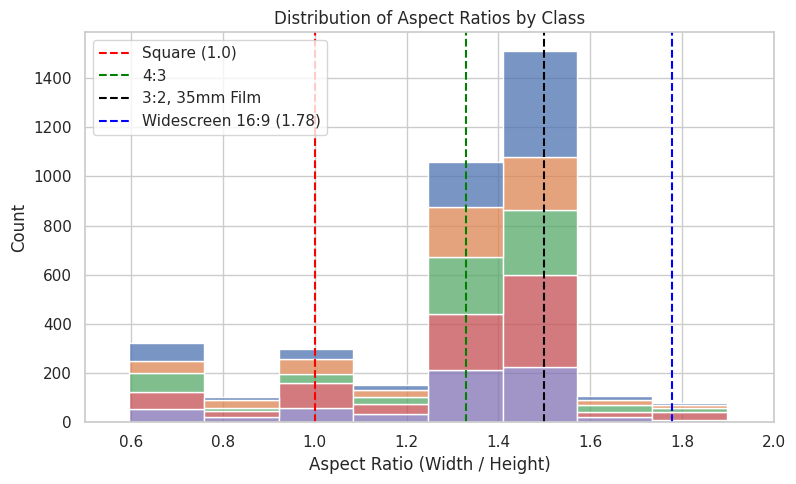

In [26]:
plt.figure(figsize=(8, 5))
# A ratio of 1.0 is a perfect square, 1.33 is 4:3, and 1.78 is 16:9
sns.histplot(data=df_image_metadata, x="Aspect_Ratio", hue="Class", multiple="stack", bins=30)
plt.axvline(1.0, color='red', linestyle='--', label='Square (1.0)')
plt.axvline(1.33, color='green', linestyle='--', label='4:3')
plt.axvline(1.5, color='black', linestyle='--', label='3:2, 35mm Film')
plt.axvline(1.777, color='blue', linestyle='--', label='Widescreen 16:9 (1.78)')
plt.title("Distribution of Aspect Ratios by Class")
plt.xlabel("Aspect Ratio (Width / Height)")
plt.legend()
plt.tight_layout()
plt.xlim(0.5, 2.0)
plt.show()

The majority of images cluster tightly between aspect ratios of approximately 1.33 and 1.5.

The single largest peak aligns directly with the 3:2 (1.5, 35mm Film) reference line (reaching around 1,500 images total across classes), followed closely by the 4:3 (~1.33) standard camera format (over 1,000 images).

Most images have an aspect ratio greater than 1.0, indicating that the dataset is predominantly composed of landscape-oriented photos.

## Pixel Intensity and Color Channels

In [19]:
class_pixels = {}

total_hist_b = np.zeros(256)
total_hist_g = np.zeros(256)
total_hist_r = np.zeros(256)

print("Calculating dataset channel histograms")
for folder in os.listdir(DATA_DIR):
    folder_path = os.path.join(DATA_DIR, folder)
    if os.path.isdir(folder_path):
        class_pixels[folder] = {
            "B": np.zeros(256),
            "G": np.zeros(256),
            "R": np.zeros(256)
        }
        for filename in tqdm(os.listdir(folder_path), desc=f"Scanning {folder}"):
            if filename.lower().endswith(valid_extensions):
                filepath = os.path.join(folder_path, filename)

                img = cv2.imread(filepath)
                if img is None:
                    continue

                # Calculate histograms for individual channels in this image
                class_pixels[folder]["B"] += cv2.calcHist([img], [0], None, [256], [0, 256]).flatten()
                class_pixels[folder]["G"] += cv2.calcHist([img], [1], None, [256], [0, 256]).flatten()
                class_pixels[folder]["R"] += cv2.calcHist([img], [2], None, [256], [0, 256]).flatten()

Calculating dataset channel histograms


Scanning roses: 100%|██████████| 641/641 [00:04<00:00, 146.47it/s]


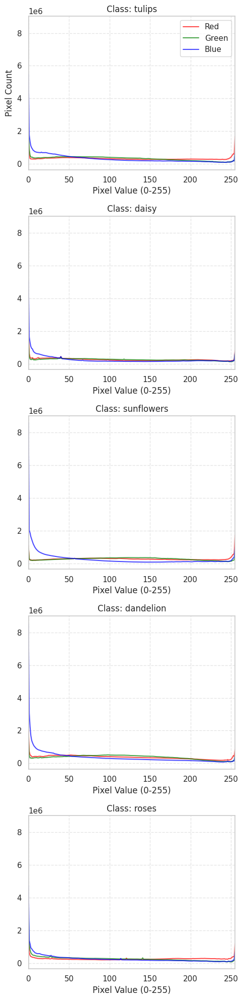

In [30]:
num_classes = len(class_pixels)
fig, axes = plt.subplots(num_classes, 1, figsize=(5, 4 * num_classes), sharey=True)

if num_classes == 1:
    axes = [axes]

for ax, (class_name, hist_data) in zip(axes, class_pixels.items()):
    ax.plot(hist_data["R"], color='red', label='Red', alpha=0.7)
    ax.plot(hist_data["G"], color='green', label='Green', alpha=0.7)
    ax.plot(hist_data["B"], color='blue', label='Blue', alpha=0.7)

    ax.set_title(f"Class: {class_name}")
    ax.set_xlabel("Pixel Value (0-255)")
    ax.set_xlim([0, 255])
    ax.grid(True, linestyle="--", alpha=0.5)
    if ax == axes[0]:
        ax.set_ylabel("Pixel Count")
        ax.legend()

axes[-1].set_xlabel("Pixel Value (0-255)")

plt.tight_layout()
plt.show()

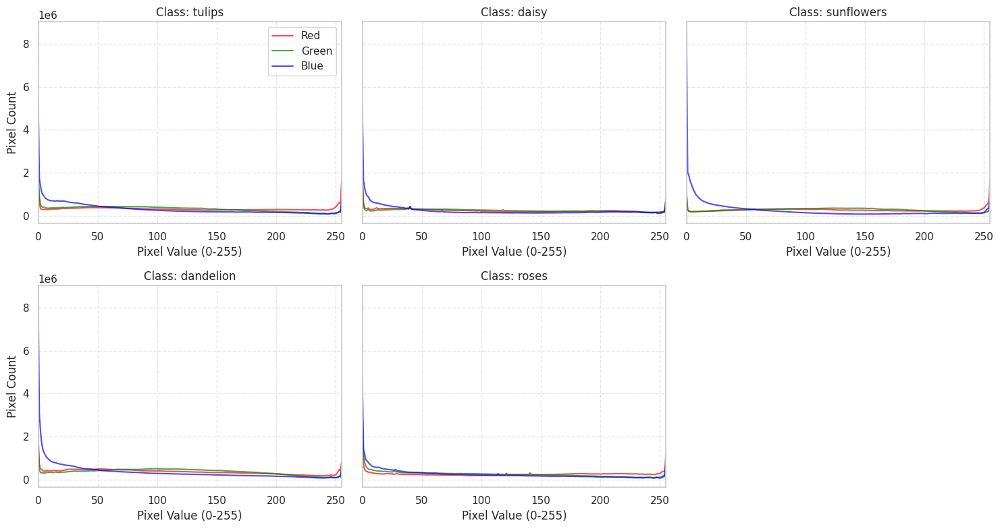

In [31]:
# 2 rows, 3 columns layout
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
axes = axes.flatten()  # Flattens the 2x3 2D array into a 1D list of 6 axes

for i, (class_name, hist_data) in enumerate(class_pixels.items()):
    ax = axes[i]
    ax.plot(hist_data["R"], color='red', label='Red', alpha=0.7)
    ax.plot(hist_data["G"], color='green', label='Green', alpha=0.7)
    ax.plot(hist_data["B"], color='blue', label='Blue', alpha=0.7)

    ax.set_title(f"Class: {class_name}")
    ax.set_xlabel("Pixel Value (0-255)")
    ax.set_xlim([0, 255])
    ax.grid(True, linestyle="--", alpha=0.5)

    # Show y-label on the leftmost plots of each row
    if i % 3 == 0:
        ax.set_ylabel("Pixel Count")

    # Legend on the first plot
    if i == 0:
        ax.legend()

# Hide any empty subplots (the 6th slot for 5 classes)
for j in range(len(class_pixels), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

**Channel-Specific Differences by Class**

Tulips, Sunflowers, and Dandelions: The Red and Green channels remain slightly higher than Blue across mid-to-high intensities (values 100–255), reflecting the natural foliage (green leaves/stems) and warm flower colors (yellows and reds).

Roses: Shows the lowest overall mid-tone volume and a pronounced Red channel lead in the upper range (>200), consistent with deep red petals against darker backgrounds.

Daisies: Shows the lowest overall pixel counts across mid-tones, pointing to either fewer samples in this split or higher overall contrast (dark greens vs. stark white highlights).

**Heavy Low-Intensity Spike (Shadows and Backgrounds)**

Every class exhibits a massive spike near pixel intensity 0–10, particularly in the Blue channel, reaching roughly $2 \times 10^6$ to over $4 \times 10^6$ counts.

This indicates a substantial amount of near-black pixels, underexposed regions, deep shadows, or dark background elements across the dataset.